# Clear-sky output: the sun's position, in SQL

**Clear-sky output** is the solar output a cloudless day would allow. It is computed, not fetched: it depends only on the time and the place, so it has no `known_at` and cannot leak. Three things lean on it: the daylight filter of every metric, the F4 check that solar is zero at night, and the clear-sky × ratio baseline and clear-sky index of step 7.

The phase-1 plan settled its form (Decisions, "Clear-sky output"): capacity × the capacity-weighted clear-sky radiation at the nine weather points ÷ 1000 W/m², in MW, with radiation from Haurwitz's formula on the sun's position, all in SQL. This notebook writes that SQL the way the dbt model will run it, then asks the data the questions that formulas can't answer.

| Question | Where |
| --- | --- |
| Does the SQL put the sun where the reference algorithm does? | Section 1 |
| When is a slot night, and does TEPCO's solar agree? | Section 2 |
| Is one sample at a slot's middle a fair stand-in for the slot's average? | Section 3 |
| On clear days, does TEPCO's solar line up in time with clear sky? | Section 4 |

It reads `dwd_tepco_actuals`, the dbt model in dev, taking each slot's latest version: targets use the latest values, so nothing here goes through `as_of`. The nine points come from `jtf.ingest.sources.WEATHER_POINTS`. Capacity weights don't exist in the warehouse yet, so where the whole area is needed the nine points weigh the same; that stand-in is named wherever it is used. Times are JST unless a column says UTC. Claims are labelled **Observed** (a cell shows it) or **Source** (with a link). [What this exploration made known](#What-this-exploration-made-known) sums it up, with what is still open.

## 0. Setup

**Step.** `sql()` runs a query against dbt's DWD dataset in dev and prints what it scanned, as in notebook 04. `sun_position(times)` writes the SQL that turns timestamps into the sun's height and the clear-sky radiation at each point. Every section reuses it, and the dbt model will be the same SQL. In order:

1. **Julian centuries** since 1 January 2000, 12:00 UTC: the clock the orbital formulas run on
2. **The sun's declination** (how far north or south of the equator it stands) and the **equation of time** (how far the sun runs ahead of or behind the clock over the year), from NOAA's equations
3. **True solar time** at each point: the UTC clock, plus the equation of time, plus 4 minutes per degree of longitude east. Its **hour angle** is 0° at solar noon and 15° per hour from it
4. **The sun's height**, from latitude, declination and hour angle. It is the geometric height: refraction, which lifts the sun's image near the horizon, is left out (section 1 measures what that costs)
5. **Haurwitz's clear-sky radiation** on the ground (GHI, global horizontal irradiance): 1098 × cos z × exp(−0.059 / cos z), where z is the sun's angle from straight up, as pvlib implements it; 0 when the sun is down

BigQuery has no degree-based trigonometry and its `MOD` takes no floats (**Observed** while writing this: "No matching signature for function MOD"), so degrees become radians by `ACOS(-1) / 180` and the wrap to one day is written with `FLOOR`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib
from google.cloud import bigquery

from jtf.ingest.sources import WEATHER_POINTS

pd.set_option("display.width", 160, "display.max_columns", 30, "display.max_colwidth", 60)


def setting(name: str) -> str:
    if value := os.environ.get(name):
        return value
    lines = Path("../.env").read_text().splitlines()
    env = dict(line.split("=", 1) for line in lines if "=" in line and not line.startswith("#"))
    return env[name]


PROJECT = setting("JTF_BIGQUERY_PROJECT")
DWD = f"{PROJECT}.{setting('JTF_DBT_DATASET_PREFIX')}_dwd"
bq = bigquery.Client(project=PROJECT)


def sql(query: str) -> pd.DataFrame:
    """Run a query against dbt's DWD dataset in dev; print what it scanned and how long it took."""
    config = bigquery.QueryJobConfig(default_dataset=DWD, use_query_cache=False)
    job = bq.query(query, job_config=config)
    rows = job.to_dataframe(create_bqstorage_client=False)
    seconds = (job.ended - job.started).total_seconds()
    print(f"[{(job.total_bytes_processed or 0) / 1e6:.1f} MB scanned, {seconds:.0f} s in BigQuery]")
    return rows


R = "(ACOS(-1) / 180)"  # degrees to radians
POINTS = (
    "SELECT * FROM UNNEST([\n"
    + ",\n".join(
        f"    STRUCT('{name}' AS point, {lat} AS lat, {lon} AS lon)"
        for name, lat, lon in WEATHER_POINTS
    )
    + "\n  ])"
)


def sun_position(times: str) -> str:
    """CTEs ending in `position`: per point and per timestamp `ts` of the CTE `times`, the sun's
    geometric height (degrees) and Haurwitz clear-sky radiation (W/m²)."""
    return f"""
points AS (
  {POINTS}
),
-- 1. Julian centuries since J2000.0
centuries AS (
  SELECT ts, (UNIX_MICROS(ts) / 8.64e10 + 2440587.5 - 2451545.0) / 36525.0 AS jc
  FROM {times}
),
orbit AS (
  SELECT
    ts, jc,
    280.46646 + jc * (36000.76983 + jc * 0.0003032) AS mean_longitude,
    357.52911 + jc * (35999.05029 - 0.0001537 * jc) AS mean_anomaly,
    0.016708634 - jc * (0.000042037 + 0.0000001267 * jc) AS eccentricity,
    23 + (26 + (21.448 - jc * (46.815 + jc * (0.00059 - jc * 0.001813))) / 60) / 60
      + 0.00256 * COS({R} * (125.04 - 1934.136 * jc)) AS obliquity
  FROM centuries
),
-- 2. Declination (degrees) and equation of time (minutes)
sun AS (
  SELECT
    ts,
    ASIN(SIN({R} * obliquity) * SIN({R} * (
      mean_longitude
      + SIN({R} * mean_anomaly) * (1.914602 - jc * (0.004817 + 0.000014 * jc))
      + SIN({R} * 2 * mean_anomaly) * (0.019993 - 0.000101 * jc)
      + SIN({R} * 3 * mean_anomaly) * 0.000289
      - 0.00569 - 0.00478 * SIN({R} * (125.04 - 1934.136 * jc))
    ))) / {R} AS declination,
    4 / {R} * (
      y * SIN(2 * {R} * mean_longitude)
      - 2 * eccentricity * SIN({R} * mean_anomaly)
      + 4 * eccentricity * y * SIN({R} * mean_anomaly) * COS(2 * {R} * mean_longitude)
      - 0.5 * y * y * SIN(4 * {R} * mean_longitude)
      - 1.25 * eccentricity * eccentricity * SIN(2 * {R} * mean_anomaly)
    ) AS equation_of_time
  FROM (SELECT *, POW(TAN({R} * obliquity / 2), 2) AS y FROM orbit)
),
-- 3. True solar time, minutes
solar_time AS (
  SELECT
    p.point, p.lat, s.ts, s.declination,
    EXTRACT(HOUR FROM s.ts) * 60 + EXTRACT(MINUTE FROM s.ts) + EXTRACT(SECOND FROM s.ts) / 60
      + s.equation_of_time + 4 * p.lon AS minutes
  FROM sun AS s CROSS JOIN points AS p
),
-- 4. The sun's height: cos z from latitude, declination and the hour angle
angles AS (
  SELECT
    point, ts,
    SIN({R} * lat) * SIN({R} * declination)
      + COS({R} * lat) * COS({R} * declination)
        * COS({R} * ((minutes - 1440 * FLOOR(minutes / 1440)) / 4 - 180)) AS cos_zenith
  FROM solar_time
),
-- 5. Haurwitz clear-sky GHI
position AS (
  SELECT
    point, ts,
    ASIN(cos_zenith) / {R} AS elevation,
    IF(cos_zenith > 0, 1098 * cos_zenith * EXP(-0.059 / cos_zenith), 0) AS clear_sky_ghi
  FROM angles
)"""


# The latest version of each slot's solar and curtailed solar, in MW.
ACTUALS = """
actuals AS (
  SELECT slot_start,
         MAX(IF(measure = 'solar', value_mw, NULL)) AS solar,
         MAX(IF(measure = 'solar_curtailed', value_mw, NULL)) AS curtailed
  FROM dwd_tepco_actuals
  WHERE known_until IS NULL
  GROUP BY slot_start
)"""

print("DWD dataset:", DWD, "| points:", ", ".join(name for name, _, _ in WEATHER_POINTS))

DWD dataset: jepx-tokyo-forecast-dev.dev_dwd | points: tokyo, yokohama, saitama, chiba, mito, utsunomiya, maebashi, kofu, numazu


## 1. The sun in SQL, against SPA

**Step.** The reference is NREL's Solar Position Algorithm (SPA) as pvlib implements it, accurate to about 0.0003° (**Source**: [pvlib `get_solarposition`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.solarposition.get_solarposition.html)). The SQL runs every 53 minutes from 1 February 2024 to 16 November 2026 at all nine points: an odd step lands on every time of day across the seasons. pvlib then computes the same instants, and its own Haurwitz on SPA's zenith. pvlib's `haurwitz` takes the *apparent* zenith, refraction included (**Source**: [pvlib `haurwitz`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.clearsky.haurwitz.html)), so the last line measures what leaving refraction out costs.

This is the slow cell: about 250,000 rows come back from BigQuery.

In [2]:
ours = sql(f"""
WITH times AS (
  SELECT ts FROM UNNEST(GENERATE_TIMESTAMP_ARRAY(
    TIMESTAMP('2024-02-01 00:00:00', 'Asia/Tokyo'), TIMESTAMP('2026-11-16 00:00:00', 'Asia/Tokyo'),
    INTERVAL 53 MINUTE)) AS ts
),
{sun_position("times")}
SELECT point, ts, elevation, clear_sky_ghi FROM position
""")

frames = []
for name, lat, lon in WEATHER_POINTS:
    o = ours[ours["point"] == name].sort_values("ts")
    spa = pvlib.solarposition.get_solarposition(
        pd.DatetimeIndex(o["ts"]), lat, lon, method="nrel_numpy"
    )
    frames.append(
        o.assign(
            spa_elevation=spa["elevation"].to_numpy(),
            spa_apparent_elevation=spa["apparent_elevation"].to_numpy(),
            pvlib_ghi=pvlib.clearsky.haurwitz(spa["zenith"]).to_numpy().ravel(),
            pvlib_ghi_apparent=pvlib.clearsky.haurwitz(spa["apparent_zenith"]).to_numpy().ravel(),
        )
    )
both = pd.concat(frames)

height = (both["elevation"] - both["spa_elevation"]).abs()
ghi = (both["clear_sky_ghi"] - both["pvlib_ghi"]).abs()
refraction = both["clear_sky_ghi"] - both["pvlib_ghi_apparent"]
near_horizon = both["spa_apparent_elevation"].between(0, 5)
pd.DataFrame(
    [
        ("Sun's height vs SPA, degrees", height.mean(), height.max()),
        ("Haurwitz vs pvlib's, same zenith, W/m²", ghi.mean(), ghi.max()),
        (
            "Geometric vs apparent zenith in Haurwitz, W/m²",
            refraction.abs().mean(),
            refraction.abs().max(),
        ),
        (
            "  of which within 5° of the horizon, W/m²",
            refraction[near_horizon].abs().mean(),
            refraction[near_horizon].abs().max(),
        ),
    ],
    columns=["comparison", "mean |difference|", "max |difference|"],
).round(4).assign(samples=len(both)).set_index("comparison").assign(
    energy_effect_pct=[
        np.nan,
        np.nan,
        round(100 * refraction.sum() / both["pvlib_ghi_apparent"].sum(), 3),
        np.nan,
    ]
)

[0.0 MB scanned, 1 s in BigQuery]


,mean |difference|,max |difference|,samples,energy_effect_pct
comparison,,,,
"Sun's height vs SPA, degrees",0.0035,0.0151,249183,NaN
"Haurwitz vs pvlib's, same zenith, W/m²",0.0242,0.2557,249183,NaN
"Geometric vs apparent zenith in Haurwitz, W/m²",0.3418,3.1682,249183,-0.131
"of which within 5° of the horizon, W/m²",2.0448,3.1682,249183,NaN


**What it shows.** **Observed**, over 249,183 samples:

- The SQL's sun stands within **0.015° of SPA** at worst, 0.0035° on average. Near the horizon the sun climbs about 0.2° a minute here (15° an hour, times the cosine of the latitude), so 0.015° is a few seconds of time: nothing, against a 30-minute slot
- Its Haurwitz radiation is within **0.26 W/m²** of pvlib's on the same zenith, against values up to about 1,000 W/m²
- Leaving refraction out changes radiation by **3.2 W/m² at most**, all of it within 5° of the horizon, and the total by **−0.13%**

**Learned → design:** the dbt model is this SQL. The geometric zenith stays: refraction would add a formula for a tenth of a percent, which the ratio baseline's scale absorbs anyway. To keep the SQL honest after this notebook, the model gets a reference check: a small seed of SPA values written by a script, and a data test that fails if the model strays from it by more than a tolerance (dbt's unit tests compare values exactly, which two implementations of floating-point trigonometry never satisfy).

## 2. Night, by the sun

### 2.1 How far the day moves

**Step.** The night check (F4: solar must be 0 at night) and the metrics' daylight filter both need to know which slots are night. The first idea is a fixed cutoff on the clock. First, how far sunrise and sunset move in Tokyo over a year: minute by minute through 2025, a sunrise or sunset is the moment the sun's centre stands at −0.833°, the standard definition (refraction and the sun's radius make it visible from there). Then the slots TEPCO itself shows output in, month by month.

In [3]:
sql(f"""
WITH times AS (
  SELECT TIMESTAMP_ADD(TIMESTAMP(day, 'Asia/Tokyo'), INTERVAL m MINUTE) AS ts
  FROM UNNEST(GENERATE_DATE_ARRAY('2025-01-01', '2025-12-31')) AS day,
       UNNEST(GENERATE_ARRAY(0, 1439)) AS m
),
{sun_position("times")},
days AS (
  SELECT DATE(ts, 'Asia/Tokyo') AS day,
         TIME(MIN(IF(elevation >= -0.833, ts, NULL)), 'Asia/Tokyo') AS sunrise,
         TIME(MAX(IF(elevation >= -0.833, ts, NULL)), 'Asia/Tokyo') AS sunset
  FROM position WHERE point = 'tokyo' GROUP BY 1
)
SELECT 'sunrise' AS event,
       MIN(sunrise) AS earliest, ARRAY_AGG(day ORDER BY sunrise LIMIT 1)[OFFSET(0)] AS earliest_on,
       MAX(sunrise) AS latest, ARRAY_AGG(day ORDER BY sunrise DESC LIMIT 1)[OFFSET(0)] AS latest_on
FROM days
UNION ALL
SELECT 'sunset', MIN(sunset), ARRAY_AGG(day ORDER BY sunset LIMIT 1)[OFFSET(0)],
       MAX(sunset), ARRAY_AGG(day ORDER BY sunset DESC LIMIT 1)[OFFSET(0)]
FROM days
""")

[0.0 MB scanned, 3 s in BigQuery]


,event,earliest,earliest_on,latest,latest_on
0,sunset,16:27:00,2025-12-01,19:01:00,2025-06-25
1,sunrise,04:25:00,2025-06-10,06:52:00,2025-01-01


In [4]:
sql(f"""
WITH {ACTUALS.strip()},
days AS (
  SELECT DATE(slot_start, 'Asia/Tokyo') AS day,
         MIN(IF(solar > 0, TIME(slot_start, 'Asia/Tokyo'), NULL)) AS first_on,
         MAX(IF(solar > 0, TIME(slot_start, 'Asia/Tokyo'), NULL)) AS last_on,
         COUNTIF(solar > 0) AS slots_on
  FROM actuals
  WHERE DATE(slot_start, 'Asia/Tokyo') BETWEEN '2025-01-01' AND '2025-12-31'
  GROUP BY 1
)
SELECT FORMAT_DATE('%m', day) AS month,
       FORMAT('%t–%t', MIN(first_on), MAX(first_on)) AS first_slot_with_output,
       FORMAT('%t–%t', MIN(last_on), MAX(last_on)) AS last_slot_with_output,
       FORMAT('%d–%d', MIN(slots_on), MAX(slots_on)) AS slots_with_output
FROM days GROUP BY 1 ORDER BY 1
""")

[3.8 MB scanned, 0 s in BigQuery]


,month,first_slot_with_output,last_slot_with_output,slots_with_output
0,01,06:30:00–07:00:00,16:30:00–17:00:00,20–22
1,02,06:00:00–06:30:00,17:00:00–17:30:00,22–24
2,03,05:30:00–06:00:00,17:30:00–17:30:00,24–25
3,04,05:00:00–05:30:00,17:30:00–18:00:00,25–27
4,05,04:30:00–05:00:00,18:00:00–18:30:00,27–29
5,06,04:30:00–04:30:00,18:30:00–18:30:00,29–29
6,07,04:30:00–05:00:00,18:30:00–18:30:00,28–29
7,08,05:00:00–05:00:00,18:00:00–18:30:00,27–28
8,09,05:00:00–05:30:00,17:00:00–18:00:00,24–27
9,10,05:30:00–06:00:00,16:30:00–17:00:00,22–24


**What it shows.** **Observed:** Tokyo's sunrise moves from 04:25 (10 June) to 06:52 (1 January), and its sunset from 16:27 (1 December) to 19:01 (25 June). TEPCO's first slot with output (labelled by its start) moves from 04:30 to 07:00, its last from 16:00 to 18:30, and the slots with output from 19 a day in December to 29 in June.

**Learned → design:** no fixed cutoff works. One wide enough for June counts about nine dark slots of every winter day as daylight: F4 could not catch output there, and the metrics would be padded with slots where forecast and actual are both 0, flattering winter accuracy and P10–P90 coverage. One narrow enough for December calls about ten summer slots with real output night: false F4 alarms every summer morning and evening. A cutoff per month still misses by a slot, because the first slot with output moves within a month. The sun's position is computed anyway, for clear-sky radiation, so night comes from it, for free.

### 2.2 The rule, against TEPCO's output

**Step.** The candidate rule: a slot is night when the sun is below the horizon **at both its edges (start and end) at all nine points**. Within a half hour near sunrise or sunset the sun only climbs or only sinks, so below at both edges means dark for the whole slot; all nine points means no panel in the area saw the sun. Equivalently: the **highest edge**, the highest the sun stands at either edge of the slot at any point, is below the horizon. Where is the horizon? 0° is geometric; −0.833° is the visible sunrise of 2.1; lower still would allow for twilight. Every slot from 1 February 2024 (the monthly files' start) to 15 November 2026 is tested against TEPCO's solar.

In [5]:
NIGHT = f"""
WITH edges AS (
  SELECT ts FROM UNNEST(GENERATE_TIMESTAMP_ARRAY(
    TIMESTAMP('2024-02-01 00:00:00', 'Asia/Tokyo'), TIMESTAMP('2026-11-16 00:00:00', 'Asia/Tokyo'),
    INTERVAL 30 MINUTE)) AS ts
),
{sun_position("edges")},
slots AS (
  SELECT a.ts AS slot_start, MAX(GREATEST(a.elevation, b.elevation)) AS highest_edge
  FROM position AS a
  JOIN position AS b ON b.point = a.point AND b.ts = TIMESTAMP_ADD(a.ts, INTERVAL 30 MINUTE)
  GROUP BY 1
),
{ACTUALS.strip()},
joined AS (SELECT * FROM slots JOIN actuals USING (slot_start) WHERE solar IS NOT NULL)
"""

sql(
    NIGHT
    + """
SELECT horizon, COUNT(*) AS slots,
       COUNTIF(highest_edge < horizon) AS night_slots,
       COUNTIF(highest_edge < horizon AND solar > 0) AS night_with_output,
       COUNTIF(highest_edge >= horizon AND solar = 0) AS daylight_without_output
FROM joined, UNNEST([0.0, -0.833, -2.0, -4.0, -6.0]) AS horizon
GROUP BY horizon ORDER BY horizon DESC
"""
)

[3.8 MB scanned, 2 s in BigQuery]


,horizon,slots,night_slots,night_with_output,daylight_without_output
0,0.000,48912,22735,0,735
1,-0.833,48912,22382,0,1088
2,-2.000,48912,22014,0,1456
3,-4.000,48912,21393,0,2077
4,-6.000,48912,20506,0,2964


In [6]:
sql(
    NIGHT
    + """
SELECT FORMAT_TIMESTAMP('%F %H:%M', slot_start, 'Asia/Tokyo') AS slot,
       ROUND(highest_edge, 2) AS highest_edge, solar
FROM joined WHERE solar > 0 ORDER BY highest_edge LIMIT 6
"""
)

[3.8 MB scanned, 2 s in BigQuery]


,slot,highest_edge,solar
0,2025-11-21 16:30,0.22,1.0
1,2025-11-20 16:30,0.31,1.0
2,2025-09-27 17:30,0.32,1.0
3,2024-11-19 16:30,0.38,1.0
4,2025-11-19 16:30,0.40,1.0
5,2024-11-18 16:30,0.48,1.0


**What it shows.** **Observed:** with the horizon at 0°, 22,735 of the 48,912 slots are night, and **TEPCO shows output in none of them**. The lowest sun with any output is +0.22°: 1 MW in the 16:30 slot of 21 November 2025, with the sun about to set at the westernmost points. Every lower horizon gives the same zero, only with fewer night slots and more daylight slots without output.

**Learned → design:** the horizon is 0°, geometric. A slot is night when the sun is below it at both edges at all nine points. F4's "solar is 0 at night" becomes a data test, and over the whole history it would not have raised one false alarm.

### 2.3 Daylight without output

**Step.** With the horizon at 0°, 735 daylight slots have no output. Which are they?

In [7]:
sql(
    NIGHT
    + """
SELECT IF(EXTRACT(HOUR FROM slot_start AT TIME ZONE 'Asia/Tokyo') < 12, 'dawn', 'dusk') AS side,
       COUNTIF(solar = 0) AS without_output, COUNTIF(solar > 0) AS with_output,
       ROUND(MAX(IF(solar = 0, highest_edge, NULL)), 2) AS highest_edge_without_output,
       ROUND(MIN(IF(solar > 0, highest_edge, NULL)), 2) AS lowest_edge_with_output
FROM joined WHERE highest_edge BETWEEN 0 AND 5
GROUP BY 1 ORDER BY 1
"""
)

[3.8 MB scanned, 2 s in BigQuery]


,side,without_output,with_output,highest_edge_without_output,lowest_edge_with_output
0,dawn,499,396,4.02,1.73
1,dusk,236,611,3.57,0.22


In [8]:
sql(
    NIGHT
    + """
SELECT FORMAT_TIMESTAMP('%F', slot_start, 'Asia/Tokyo') AS day,
       ROUND(highest_edge, 2) AS highest_edge_0430, solar AS solar_0430
FROM joined
WHERE FORMAT_TIMESTAMP('%H:%M', slot_start, 'Asia/Tokyo') = '04:30'
  AND FORMAT_TIMESTAMP('%F', slot_start, 'Asia/Tokyo') BETWEEN '2025-05-06' AND '2025-05-20'
ORDER BY 1
"""
)

[3.8 MB scanned, 2 s in BigQuery]


,day,highest_edge_0430,solar_0430
0,2025-05-06,2.97,0.0
1,2025-05-07,3.15,0.0
2,2025-05-08,3.32,0.0
3,2025-05-09,3.50,0.0
4,2025-05-10,3.67,0.0
5,2025-05-11,3.83,0.0
6,2025-05-12,3.99,0.0
7,2025-05-13,4.14,1.0
8,2025-05-14,4.29,1.0
9,2025-05-15,4.43,1.0


**What it shows.** **Observed:**

- All 735 slots have the sun low: under 4.1° at their higher edge. The highest ones are the 04:30 slot on 10–12 May, in 2024, 2025 and 2026 alike. The repetition by date looked like a rule in TEPCO's estimates, but the 04:30 slot simply turns from 0 MW to 1 MW on 13 May 2025, as the sun at the slot's end passes 4°. It repeats by date because the sun's path does
- A reading, not tested here: such a slot gets only minutes of sun a few degrees up, rising in the east-north-east in May, behind panels tilted to the south (if most of them are); its average rounds to 0 in whole MW
- **Dawn and dusk differ.** Among slots whose higher edge is within 5° of the horizon, output at dawn starts only once the sun reaches 1.73°, while at dusk it lasts until 0.22°. Morning and evening should mirror each other. One reading is that TEPCO's values sit later on the clock than "labelled by the slot's start" places them; section 4 tests that

**Learned → design:** these slots stay daylight. They hold nearly no energy, so they barely move any metric, and dropping them would need a second threshold the data doesn't call for.

## 3. One sample or six

**Step.** TEPCO's values are averages over the slot, so clear-sky radiation per slot should be an average too. The plan said "at each slot's middle", one sample. Through 2025, at all nine points, the reference is the average of 30 samples at the middle of each minute; against it, the single middle sample (minute 15) and the average of six samples at the middles of each 5 minutes (minutes 2.5, 7.5, …, 27.5). Grouped by how much light the slot holds.

In [9]:
sql(f"""
WITH samples AS (
  SELECT slot_start, kind, TIMESTAMP_ADD(slot_start, INTERVAL offset_s SECOND) AS ts
  FROM UNNEST(GENERATE_DATE_ARRAY('2025-01-01', '2025-12-31')) AS day,
       UNNEST(GENERATE_ARRAY(0, 47)) AS slot,
       UNNEST([TIMESTAMP_ADD(TIMESTAMP(day, 'Asia/Tokyo'), INTERVAL 30 * slot MINUTE)])
         AS slot_start,
       UNNEST(ARRAY_CONCAT(
         ARRAY(SELECT AS STRUCT 'reference' AS kind, 30 + 60 * i AS offset_s
               FROM UNNEST(GENERATE_ARRAY(0, 29)) AS i),
         ARRAY(SELECT AS STRUCT 'six' AS kind, 150 + 300 * i AS offset_s
               FROM UNNEST(GENERATE_ARRAY(0, 5)) AS i),
         [STRUCT('middle' AS kind, 900 AS offset_s)]))
),
times AS (SELECT DISTINCT ts FROM samples),
{sun_position("times")},
slots AS (
  SELECT p.point, s.slot_start,
         AVG(IF(s.kind = 'reference', p.clear_sky_ghi, NULL)) AS reference,
         AVG(IF(s.kind = 'six', p.clear_sky_ghi, NULL)) AS six,
         AVG(IF(s.kind = 'middle', p.clear_sky_ghi, NULL)) AS middle
  FROM samples AS s JOIN position AS p USING (ts)
  GROUP BY 1, 2
)
SELECT
  CASE WHEN reference = 0 THEN '1. dark' WHEN reference < 50 THEN '2. under 50 W/m²'
       WHEN reference < 300 THEN '3. 50–300 W/m²' ELSE '4. 300 W/m² and up' END AS light,
  COUNT(*) AS slots,
  ROUND(AVG(ABS(middle - reference)), 3) AS middle_mean_abs,
  ROUND(MAX(ABS(middle - reference)), 2) AS middle_max_abs,
  ROUND(100 * SUM(middle - reference) / NULLIF(SUM(reference), 0), 2) AS middle_bias_pct,
  COUNTIF(middle = 0 AND reference > 0) AS middle_dark_but_lit,
  ROUND(AVG(ABS(six - reference)), 3) AS six_mean_abs,
  ROUND(MAX(ABS(six - reference)), 2) AS six_max_abs,
  ROUND(100 * SUM(six - reference) / NULLIF(SUM(reference), 0), 2) AS six_bias_pct,
  COUNTIF(six = 0 AND reference > 0) AS six_dark_but_lit
FROM slots GROUP BY 1 ORDER BY 1
""")

[0.0 MB scanned, 13 s in BigQuery]


,light,slots,middle_mean_abs,middle_max_abs,middle_bias_pct,middle_dark_but_lit,six_mean_abs,six_max_abs,six_bias_pct,six_dark_but_lit
0,1. dark,75550,0.000,0.00,NaN,0,0.000,0.00,NaN,0
1,2. under 50 W/m²,8794,2.955,7.19,-22.27,2950,0.074,0.12,-0.55,443
2,3. 50–300 W/m²,16919,0.270,1.55,-0.05,0,0.008,0.06,-0.00,0
3,4. 300 W/m² and up,56417,0.467,0.64,0.07,0,0.012,0.02,0.00,0


**What it shows.** **Observed** (W/m², 2025, nine points):

- Above 50 W/m², one sample at the middle is within 1.6 W/m² of the average, under 0.1% either way
- **Below 50 W/m², the middle reads 22% low**, by up to 7 W/m², and calls 2,950 slots dark that have the sun up for part of them: the dawn and dusk slots, where light rises steeply within the half hour
- Six samples read **0.55% low** there, by 0.12 W/m² at most, and call 443 slots dark (the sun up only in a slot's first or last 2.5 minutes)

**Learned → design:** clear-sky radiation per slot is **the mean of six samples** at the 5-minute middles, not one sample at the slot's middle. The ratio baseline and the clear-sky index both divide by clear sky, so a value 22% too low at dawn and dusk would inflate exactly those slots. Six samples cost nothing that is billed: the sun's position is computed, not read, so the query scans no bytes. This changes the plan's "at each slot's middle".

## 4. Clear days, in time

### 4.1 The centre of a clear day

**Step.** Section 2.3 left a question: are TEPCO's values where "labelled by the slot's start" puts them on the clock? On a cloudless day, output rises and falls around solar noon in step with clear sky, so the **centre of the day's output in time** (each slot's value placed at its middle, weighted by MW) should sit on the centre of clear-sky radiation. If TEPCO's labels were slot ends, every value would be placed 30 minutes late, and so would the centre.

Clear days come from the data: for each month, the 10% of days with the most output (delivered + curtailed: what the sky allowed) for their clear-sky energy. The area's clear sky is the nine points weighing the same, a stand-in for capacity weights; minute by minute, from 1 February 2024 to 15 November 2026.

In [10]:
CLEAR_DAYS = f"""
WITH times AS (
  SELECT TIMESTAMP_ADD(TIMESTAMP(day, 'Asia/Tokyo'), INTERVAL m MINUTE) AS ts
  FROM UNNEST(GENERATE_DATE_ARRAY('2024-02-01', '2026-11-15')) AS day,
       UNNEST(GENERATE_ARRAY(0, 1439)) AS m
),
{sun_position("times")},
area AS (SELECT ts, AVG(clear_sky_ghi) AS clear_sky FROM position GROUP BY ts),
clear_sky_days AS (
  SELECT DATE(ts, 'Asia/Tokyo') AS day, SUM(clear_sky) AS clear_sky_energy,
         SUM(clear_sky * (EXTRACT(HOUR FROM ts AT TIME ZONE 'Asia/Tokyo') * 60
                          + EXTRACT(MINUTE FROM ts AT TIME ZONE 'Asia/Tokyo') + 0.5))
           / SUM(clear_sky)
           AS clear_sky_centre
  FROM area GROUP BY 1
),
{ACTUALS.strip()},
output_days AS (
  SELECT DATE(slot_start, 'Asia/Tokyo') AS day,
         SUM(IFNULL(solar, 0) + IFNULL(curtailed, 0)) AS energy,
         SUM((IFNULL(solar, 0) + IFNULL(curtailed, 0))
             * (EXTRACT(HOUR FROM slot_start AT TIME ZONE 'Asia/Tokyo') * 60
                + EXTRACT(MINUTE FROM slot_start AT TIME ZONE 'Asia/Tokyo') + 15))
           / SUM(IFNULL(solar, 0) + IFNULL(curtailed, 0)) AS output_centre
  FROM actuals GROUP BY 1 HAVING COUNT(*) = 48
),
days AS (
  SELECT o.day, o.output_centre - c.clear_sky_centre AS offset_minutes,
         PERCENT_RANK() OVER (PARTITION BY FORMAT_DATE('%Y-%m', o.day)
                              ORDER BY o.energy / c.clear_sky_energy) AS clearness_rank
  FROM output_days AS o JOIN clear_sky_days AS c USING (day)
)
"""

sql(
    CLEAR_DAYS
    + """
SELECT FORMAT_DATE('%m', day) AS month, COUNT(*) AS clear_days,
       ROUND(APPROX_QUANTILES(offset_minutes, 2)[OFFSET(1)], 1) AS median_offset_minutes,
       ROUND(MIN(offset_minutes), 1) AS min_offset, ROUND(MAX(offset_minutes), 1) AS max_offset
FROM days WHERE clearness_rank >= 0.9
GROUP BY 1 ORDER BY 1
"""
)

[3.8 MB scanned, 24 s in BigQuery]


,month,clear_days,median_offset_minutes,min_offset,max_offset
0,01,8,4.6,2.7,5.8
1,02,9,4.4,3.5,7.3
2,03,12,4.3,-0.2,5.9
3,04,9,2.5,-2.2,9.3
4,05,12,1.8,-2.2,8.4
5,06,9,-1.5,-9.2,5.9
6,07,12,-0.5,-8.5,4.6
7,08,12,1.1,-0.7,9.4
8,09,9,-0.2,-8.2,29.5
9,10,12,1.5,-10.0,11.8


**What it shows.** **Observed:** month by month, the median clear day's output is centred between **1.5 minutes early and 4.8 minutes late** of clear sky. Slot-end labels would put it about 30 minutes late. One September day sits 29.5 minutes late, but its month's median is −0.2: probably a day with a cloudy morning ranked among the clear ones (not checked), not a shift of the clock.

**Learned → design:** TEPCO's labels are slot starts, as the PRD says, and DWD keeps them so. The dawn–dusk difference of 2.3 is in the fleet, not the clock. What remains, a centre 4–5 minutes late in winter and on time in summer, is listed as still open: equal weights stand in for capacity weights here, and morning dew or frost and afternoon heat are candidates that this data can't separate.

### 4.2 One clear day in June, one in December

**Step.** The clearest day of June 2025 and of December 2025 by the same ranking, each slot's output and clear-sky radiation (six samples, nine points weighing the same) scaled to their own peak, so the shapes compare without capacity. This is a look at the shape, not a measurement of it: what panel tilt does to the shape belongs to the features notebook.

[3.8 MB scanned, 28 s in BigQuery]


[3.8 MB scanned, 0 s in BigQuery]


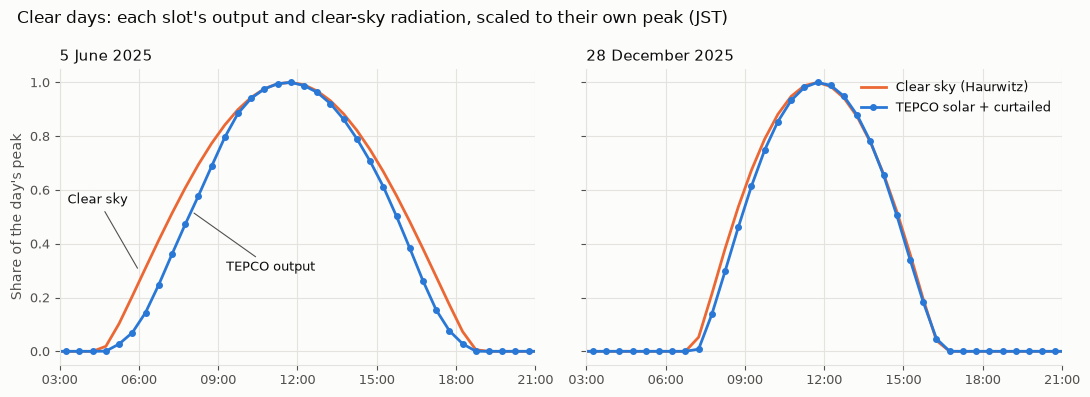

In [11]:
picked = sql(
    CLEAR_DAYS
    + """
SELECT day FROM (
  SELECT day, ROW_NUMBER() OVER (
    PARTITION BY FORMAT_DATE('%Y-%m', day) ORDER BY clearness_rank DESC) AS n
  FROM days WHERE FORMAT_DATE('%Y-%m', day) IN ('2025-06', '2025-12')
) WHERE n = 1 ORDER BY day
"""
)["day"].tolist()
day_list = ", ".join(f"'{d}'" for d in picked)

shapes = sql(f"""
WITH samples AS (
  SELECT slot_start, TIMESTAMP_ADD(slot_start, INTERVAL 150 + 300 * i SECOND) AS ts
  FROM UNNEST([{day_list}]) AS day_text,
       UNNEST(GENERATE_ARRAY(0, 47)) AS slot,
       UNNEST([TIMESTAMP_ADD(TIMESTAMP(DATE(day_text), 'Asia/Tokyo'), INTERVAL 30 * slot MINUTE)])
         AS slot_start,
       UNNEST(GENERATE_ARRAY(0, 5)) AS i
),
times AS (SELECT DISTINCT ts FROM samples),
{sun_position("times")},
sky AS (
  SELECT s.slot_start, AVG(p.clear_sky_ghi) AS clear_sky
  FROM samples AS s JOIN position AS p USING (ts) GROUP BY 1
),
{ACTUALS.strip()}
SELECT DATE(slot_start, 'Asia/Tokyo') AS day,
       TIMESTAMP_ADD(slot_start, INTERVAL 15 MINUTE) AS slot_middle,
       IFNULL(solar, 0) + IFNULL(curtailed, 0) AS output_mw, clear_sky
FROM sky JOIN actuals USING (slot_start)
ORDER BY slot_start
""")

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
OUTPUT, CLEAR = "#2a78d6", "#eb6834"  # categorical slots 1 and 2, validated for this surface

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, facecolor=SURFACE)
for ax, (day, d) in zip(axes, shapes.groupby("day"), strict=True):
    hours = (
        d["slot_middle"].dt.tz_convert("Asia/Tokyo").dt.hour
        + d["slot_middle"].dt.tz_convert("Asia/Tokyo").dt.minute / 60
    )
    ax.set_facecolor(SURFACE)
    ax.plot(
        hours,
        d["clear_sky"] / d["clear_sky"].max(),
        color=CLEAR,
        lw=2,
        label="Clear sky (Haurwitz)",
    )
    ax.plot(
        hours,
        d["output_mw"] / d["output_mw"].max(),
        color=OUTPUT,
        lw=2,
        marker="o",
        ms=4,
        label="TEPCO solar + curtailed",
    )
    ax.set_title(f"{day:%-d %B %Y}", color=INK, fontsize=11, loc="left")
    ax.set_xlim(3, 21)
    ax.set_xticks(range(3, 22, 3), [f"{h:02d}:00" for h in range(3, 22, 3)])
    ax.grid(color=GRID, lw=0.8)
    ax.tick_params(colors=MUTED, labelsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
axes[0].set_ylabel("Share of the day's peak", color=MUTED)
axes[1].legend(frameon=False, loc="upper right", fontsize=9, labelcolor=INK)
leader = dict(arrowstyle="-", color=MUTED, lw=0.8)
axes[0].annotate(
    "Clear sky", xy=(6.0, 0.30), xytext=(3.3, 0.55), color=INK, fontsize=9, arrowprops=leader
)
axes[0].annotate(
    "TEPCO output", xy=(8.0, 0.52), xytext=(9.3, 0.30), color=INK, fontsize=9, arrowprops=leader
)
fig.suptitle(
    "Clear days: each slot's output and clear-sky radiation, scaled to their own peak (JST)",
    color=INK,
    fontsize=12,
    x=0.02,
    ha="left",
)
fig.tight_layout()
plt.show()

**What it shows.** **Observed:** on both days the output rises and falls with clear sky, with the peaks in the same slot; nothing is shifted by a slot, which a labelling or time-zone error would do. The shapes are not the same. In June the output is narrower than clear sky, lower on both shoulders (at 07:00 about 0.25 of its peak, against 0.42 for clear sky); in December the two nearly coincide. A reading, not measured here: panels tilted to the south would do exactly this, since in June the sun rises and sets well to the north of east and west, behind them, while in December it stays in the south.

**Learned → design:** nothing new for the model: the clock is right, and the difference in shape is what the ratio baseline and the model's features exist to absorb. Measuring it, and whether tilt explains it, is the features notebook's job.

## The dbt models this leads to

| Model | One row per | Columns besides the key | Notes |
| --- | --- | --- | --- |
| seed `weather_points` | Point | `lat`, `lon` | The same nine points as `WEATHER_POINTS`; a pytest fails if the two ever differ, so there is one definition |
| `dwd_sun_slots` | Point, slot (`slot_start`) | `elevation_start`, `elevation_end` (degrees, geometric), `clear_sky_ghi` (W/m², the mean of six samples) | From 2016 to a fixed end well past today: computed, so no `known_at`, and no clock read |
| `dwd_daylight` | Slot | `is_night`: the sun below 0° at both edges at all nine points | The daylight filter of the metrics and the F4 check |
| `dws_solar_features` | Decision time, slot | `clear_sky_mw`: capacity × the capacity-weighted `clear_sky_ghi` ÷ 1000 | Waits for `dwd_capacity_releases`: the weights and the capacity are known as of `T` |

Tests:

- A seed of SPA values (a few days a year at every point, written by a script with pvlib) and a data test that `dwd_sun_slots` stays within 0.05° and 1 W/m² of it
- **F4 as a data test:** no slot with `is_night` has solar above 0 in `dwd_tepco_actuals` (none in the history, section 2.2)
- Every slot of the range has nine points, 48 slots a day; `clear_sky_ghi` is 0 exactly when both edges are below the horizon at that point

## What this exploration made known

| We assumed | We found | So |
| --- | --- | --- |
| Night could be a fixed time on the clock | TEPCO's first slot with output moves from 04:30 to 07:00 over the year, its last from 16:00 to 18:30, and the slots with output from 19 to 29 a day (section 2.1) | Night comes from the sun's position, which clear sky needs anyway |
| Twilight might need a horizon below 0° | With the horizon at 0°, none of 22,735 night slots since February 2024 has output; the lowest sun with output is +0.22° (section 2.2) | A slot is night when the sun is below 0° at both its edges at all nine points. F4 becomes a data test that would never have fired falsely |
| A daylight slot always has some output | 735 daylight slots have none, every one with the sun under 4.1°; the May 04:30 slot turns to 1 MW as the sun at its end passes 4° (section 2.3) | Whole-MW rounding of a few minutes of low sun, not a rule of TEPCO's. They stay daylight |
| TEPCO labels slots by their start (PRD) | Dawn and dusk differ (output from 1.73° at dawn, until 0.22° at dusk), which slot-end labels would explain; but each month's clear days are centred within −1.5 to +4.8 minutes of clear sky, where slot-end labels would put them 30 minutes late (sections 2.3, 4.1) | The labels are slot starts. The difference is in the fleet, not the clock |
| One sample at a slot's middle stands in for its average (plan) | Above 50 W/m² it does, within 1.6 W/m²; below, it reads 22% low and calls 2,950 lit slots dark in 2025. Six samples read 0.55% low, within 0.12 W/m² (section 3) | **Clear sky per slot is the mean of six samples**, a change from the plan's "at each slot's middle", for the plan to take up |
| Haurwitz should take the apparent zenith, as pvlib's does | Geometric and apparent differ by 3.2 W/m² at most, all within 5° of the horizon: −0.13% of the energy (section 1) | The geometric zenith stays |
| Trigonometry in SQL might drift from a reference implementation | Within 0.015° of SPA and 0.26 W/m² of pvlib's Haurwitz, over 249,183 samples (section 1) | The dbt model is this SQL, kept honest by a seed of SPA values and a test with a tolerance |

### Still open

- **Why dawn and dusk differ.** Output starts only once the sun reaches 1.73°, but lasts until it is down to 0.22°. Candidates: dew or frost on morning panels, and inverters that wait some minutes after first light before connecting to the grid. Nothing here tests either
- **Why clear days are centred 4–5 minutes late in winter and on time in summer.** Equal weights stand in for capacity weights here; morning dew or frost and afternoon heat are candidates. Worth a second look once `dwd_capacity_releases` gives the real weights
- **The shape: what panel tilt does to it.** In June the output is narrower than clear sky on a flat surface, in December nearly the same (section 4.2), as south-tilted panels would make it. The features notebook measures it, as the plan says

## Where the sources and the data disagree

| Where | Says | We found | Handled by |
| --- | --- | --- | --- |
| Phase-1 plan, Decisions | Clear-sky radiation "at each slot's middle" | One sample reads 22% low in the dawn and dusk slots (section 3) | Six samples per slot; the plan to be updated |
| Phase-1 plan, Model and evaluation | Metrics on "daylight slots only (sun elevation above 0)" | The sun's height differs across a slot and across the area, so the rule needs both (section 2.2) | Night: below 0° at both edges at all nine points; daylight is every other slot |
| [pvlib `haurwitz`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.clearsky.haurwitz.html) | Takes the apparent zenith | The geometric one is within 0.13% of the energy (section 1) | Geometric kept |

## Sources

| Page | Supports |
| --- | --- |
| [NOAA Global Monitoring Laboratory, solar calculation details](https://gml.noaa.gov/grad/solcalc/calcdetails.html) | The equations of section 0: declination, equation of time, true solar time, hour angle, and −0.833° for sunrise and sunset |
| [pvlib `get_solarposition`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.solarposition.get_solarposition.html) | SPA as the reference; geometric and apparent elevation |
| [pvlib `haurwitz`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.clearsky.haurwitz.html) | Haurwitz's clear-sky formula and its input, the apparent zenith |
| [BigQuery mathematical functions](https://cloud.google.com/bigquery/docs/reference/standard-sql/mathematical_functions) | Trigonometry in radians; `MOD` for integers and numerics only |
| [TEPCO area supply and demand](https://www.tepco.co.jp/forecast/html/area_jukyu-j.html) | The monthly actuals: MW averaged over each slot, labelled by its start |